# PanEcho EchoNet-Dynamic Evaluation

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import DataLoader

PROJECT_ROOT = next(
    parent for parent in [Path.cwd(), *Path.cwd().parents]
    if (parent / "src").is_dir()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.datasets.panecho_echonet_dataset import PanEchoEchoNetDataset, load_echonet_records
from src.models.echo.panecho import load_panecho
from src.evaluation.evaluate_echo_panecho import predict_loader, summarize
from src.evaluation.metrics import ef_threshold_metrics, regression_metrics

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


In [2]:
MANIFEST_PATH = PROJECT_ROOT / "data" / "processed" / "echo" / "echonet" / "echonet_manifest.csv"
PRETRAINED_CHECKPOINT = PROJECT_ROOT / "checkpoints" / "echo" / "panecho.pt"
FINE_TUNED_CHECKPOINT = PROJECT_ROOT / "checkpoints" / "echo" / "panecho" / "panecho_echonet_finetuned.pt"
RESULTS_DIR = PROJECT_ROOT / "artifacts" / "metrics" / "echo" / "panecho"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Manifest:", MANIFEST_PATH)
print("Fine-tuned checkpoint:", FINE_TUNED_CHECKPOINT)
print("Pretrained checkpoint:", PRETRAINED_CHECKPOINT)

Manifest: d:\Programming\VS Code\Projects\CardioFusion-XAI\ml-service\data\processed\echo\echonet\echonet_manifest.csv
Fine-tuned checkpoint: d:\Programming\VS Code\Projects\CardioFusion-XAI\ml-service\checkpoints\echo\panecho\panecho_echonet_finetuned.pt
Pretrained checkpoint: d:\Programming\VS Code\Projects\CardioFusion-XAI\ml-service\checkpoints\echo\panecho.pt


In [3]:
if not FINE_TUNED_CHECKPOINT.exists():
    raise FileNotFoundError(
        f"Fine-tuned PanEcho checkpoint missing: {FINE_TUNED_CHECKPOINT}"
    )

records = load_echonet_records(
    manifest=MANIFEST_PATH,
    project_root=PROJECT_ROOT,
)
dataset = PanEchoEchoNetDataset(records, split="test", num_clips=4, augment=False)
loader = DataLoader(dataset, batch_size=2, shuffle=False, num_workers=2)

model = load_panecho(FINE_TUNED_CHECKPOINT, tasks="auto", device=DEVICE)
print("Loaded fine-tuned PanEcho heads:", model.task_names)

predictions = predict_loader(model, loader, DEVICE)
print(predictions.head())

Loaded fine-tuned PanEcho heads: ['EF']


                                          video_path    EF_pred    EF_true
0  D:\Programming\VS Code\Projects\CardioFusion-X...  59.968750  55.951790
1  D:\Programming\VS Code\Projects\CardioFusion-X...  36.878906  41.014423
2  D:\Programming\VS Code\Projects\CardioFusion-X...  56.484375  50.794720
3  D:\Programming\VS Code\Projects\CardioFusion-X...  46.781250  50.634983
4  D:\Programming\VS Code\Projects\CardioFusion-X...  59.554688  63.098087


In [4]:
metrics = summarize(predictions)

output_dir = RESULTS_DIR / "finetuned"
output_dir.mkdir(parents=True, exist_ok=True)
predictions.to_csv(output_dir / "predictions.csv", index=False)
(output_dir / "metrics.json").write_text(
    json.dumps({"checkpoint": str(FINE_TUNED_CHECKPOINT), "split": "test", "num_clips": 4, **metrics}, indent=2),
    encoding="utf-8",
)

print(json.dumps(metrics, indent=2))

{
  "n_videos": 182,
  "EF_MAE": 5.0702226135756945,
  "EF_RMSE": 7.334132096753461,
  "EF_R2": 0.6271833473569632,
  "EF_<50_Accuracy": 0.9175824175824175,
  "EF_<40_Accuracy": 0.945054945054945,
  "EF_<50_auroc": 0.9343750000000001,
  "EF_<50_auprc": 0.8007152424772154,
  "EF_<50_f1": 0.7368421052631579,
  "EF_<50_precision": 0.84,
  "EF_<50_recall": 0.65625,
  "EF_<40_auroc": 0.9681571815718157,
  "EF_<40_auprc": 0.7985614640324787,
  "EF_<40_f1": 0.6666666666666666,
  "EF_<40_precision": 0.8333333333333334,
  "EF_<40_recall": 0.5555555555555556
}


In [5]:
for metric_name in ("EF_MAE", "EF_RMSE", "EF_R2"):
    if metric_name in metrics:
        print(f"{metric_name}: {metrics[metric_name]:.4f}")

comparison = predictions.rename(columns={
    "EF_true": "true_EF",
    "EF_pred": "predicted_EF",
})
comparison["absolute_error"] = (
    comparison["true_EF"] - comparison["predicted_EF"]
).abs()

display(comparison.head())
print("EF < 50 acc:", metrics.get("EF_<50_Accuracy"))
print("EF < 40 acc:", metrics.get("EF_<40_Accuracy"))

EF_MAE: 5.0702
EF_RMSE: 7.3341
EF_R2: 0.6272


,video_path,predicted_EF,true_EF,absolute_error
0,D:\Programming\VS Code\Projects\CardioFusion-X...,59.968750,55.951790,4.016960
1,D:\Programming\VS Code\Projects\CardioFusion-X...,36.878906,41.014423,4.135517
2,D:\Programming\VS Code\Projects\CardioFusion-X...,56.484375,50.794720,5.689655
3,D:\Programming\VS Code\Projects\CardioFusion-X...,46.781250,50.634983,3.853733
4,D:\Programming\VS Code\Projects\CardioFusion-X...,59.554688,63.098087,3.543400


EF < 50 acc: 0.9175824175824175
EF < 40 acc: 0.945054945054945


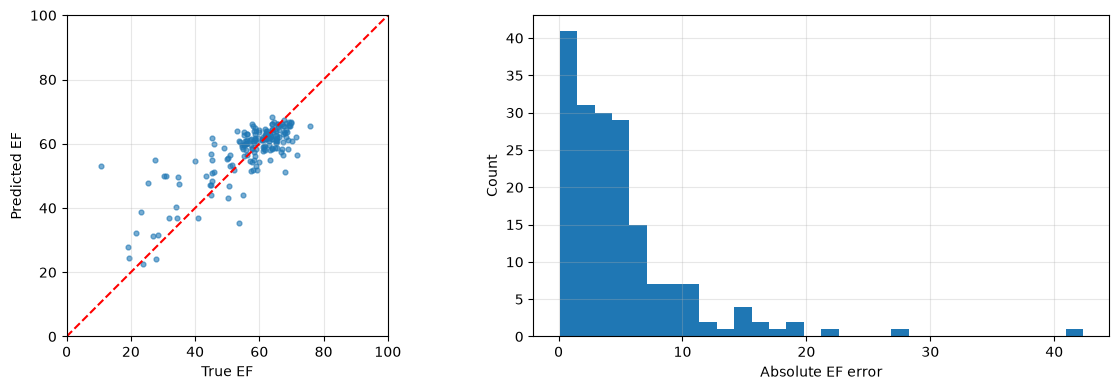

In [6]:
if {"true_EF", "predicted_EF"}.issubset(comparison.columns):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].scatter(comparison["true_EF"], comparison["predicted_EF"], s=12, alpha=0.6)
    axes[0].plot([0, 100], [0, 100], "r--")
    axes[0].set_xlabel("True EF")
    axes[0].set_ylabel("Predicted EF")
    axes[0].set_xlim(0, 100)
    axes[0].set_ylim(0, 100)
    axes[0].set_aspect("equal")
    axes[0].grid(alpha=0.3)

    axes[1].hist(comparison["absolute_error"], bins=30)
    axes[1].set_xlabel("Absolute EF error")
    axes[1].set_ylabel("Count")
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()